#  **Jarque-Bera**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.stats import skew, kurtosis, chi2, jarque_bera
import yfinance as yf
from scipy.stats import norm


14


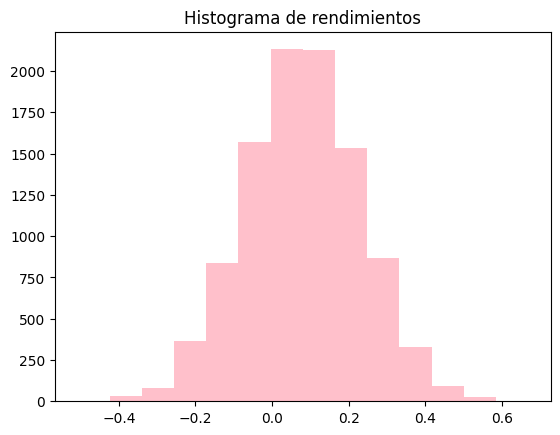

In [2]:
# Simular datos normales
np.random.seed(42)
rendimientos = np.random.normal(0.08,0.15,10000)

# Numero minimo de clases segun la regla de sturge
largo = len(rendimientos)
c = math.log(largo)/math.log(2)

# Entero más cercano hacia arriba
c = math.ceil(c)
print(c)

# Realizar histograma
plt.title("Histograma de rendimientos")

plt.hist(rendimientos, bins=c, color = "pink")
plt.show()

In [3]:
# Media
Mu = sum(rendimientos)/largo
print("El rendimiento esperado diario es de:", Mu)

# Desviación estandar
DE = math.sqrt(sum((rendimientos - Mu)**2)/(largo - 1))
print("La desviación estandar diaria es de:", DE)

# Sesgo
S = (largo/((largo-1)*(largo-2))) * sum(((rendimientos - Mu)/DE)**3)
print("El sesgo diario es de:", S)

# Kurtosis
K = (sum((rendimientos - Mu)**4))/((largo-1)*DE**4)
print("La kurtosis diaria es de:", K)

El rendimiento esperado diario es de: 0.0796796024947361
La desviación estandar diaria es de: 0.1505193570755105
El sesgo diario es de: 0.0019639923774881127
La kurtosis diaria es de: 3.026176624433209


In [4]:
# Prueba de hipotesis Jarque-Bera

# Calcular el estadistico
JB = largo*(S**2/6 + (K-3)**2/24)

# p_value
p_value = chi2.sf(JB, 2)

# valor de significancia del 0.05
alfa = 0.05

print("El estadistico de Jarque-Bera es de:", JB)
print("El p_value es de:", p_value)
print("Con un nivel de significancia", alfa, "se tiene que:")

if p_value > alfa:
    print("No rechazamos la hipotesis H0 ya que p_value= ", p_value, "> alfa =", alfa)
else:
    print("Rechazamos la hipotesis H0 ya que p_value= ", p_value, "<= alfa =", alfa)

El estadistico de Jarque-Bera es de: 0.2919353045635859
El p_value es de: 0.8641856571666331
Con un nivel de significancia 0.05 se tiene que:
No rechazamos la hipotesis H0 ya que p_value=  0.8641856571666331 > alfa = 0.05


In [5]:
JB_python, p_value_python = jarque_bera(rendimientos)

print("El estadistico de Jarque-Bera es de:", JB_python)
print("El p_value es de:", p_value_python)

if p_value_python > alfa:
    print("No rechazamos la hipotesis H0 ya que p_value= ", p_value_python, "> alfa =", alfa)
    print("La distribucion es normal")
else:
    print("Rechazamos la hipotesis H0 ya que p_value= ", p_value_python, "<= alfa =", alfa)
    print("La distribucion no es normal")

El estadistico de Jarque-Bera es de: 0.29857345850371914
El p_value es de: 0.86132211324421
No rechazamos la hipotesis H0 ya que p_value=  0.86132211324421 > alfa = 0.05
La distribucion es normal


**Datos reales**

In [6]:
import yfinance as yf

In [7]:
df_precios = pd.DataFrame()

activos = "LIVEPOLC-1.MX"

df_precios["Accion"] = pd.DataFrame(yf.Ticker(activos).history(start="2023-09-28", end="2025-09-26")["Close"])

df_precios

,Accion
Date,
2023-09-28 00:00:00-06:00,86.966072
2023-09-29 00:00:00-06:00,86.520287
2023-10-02 00:00:00-06:00,87.165253
2023-10-03 00:00:00-06:00,86.434914
2023-10-04 00:00:00-06:00,85.998611
...,...
2025-09-19 00:00:00-06:00,91.962975
2025-09-22 00:00:00-06:00,92.742401
2025-09-23 00:00:00-06:00,93.600769


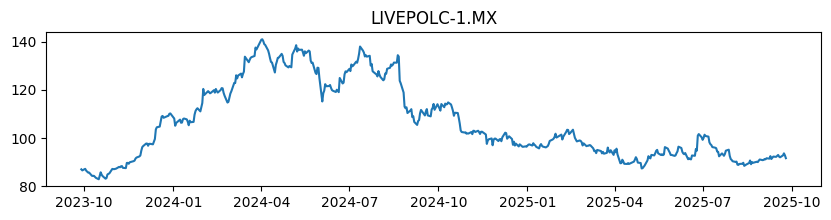

In [8]:
plt.figure(figsize=(10,2))
plt.title("LIVEPOLC-1.MX")
plt.plot(df_precios)
plt.show()

In [9]:
df_precios["Rendimientos"] = np.log(df_precios["Accion"]/df_precios["Accion"].shift(1))

df_precios.dropna(inplace=True)
df_precios


,Accion,Rendimientos
Date,,
2023-09-29 00:00:00-06:00,86.520287,-0.005139
2023-10-02 00:00:00-06:00,87.165253,0.007427
2023-10-03 00:00:00-06:00,86.434914,-0.008414
2023-10-04 00:00:00-06:00,85.998611,-0.005061
2023-10-05 00:00:00-06:00,85.619225,-0.004421
...,...,...
2025-09-19 00:00:00-06:00,91.962975,-0.003106
2025-09-22 00:00:00-06:00,92.742401,0.008440
2025-09-23 00:00:00-06:00,93.600769,0.009213


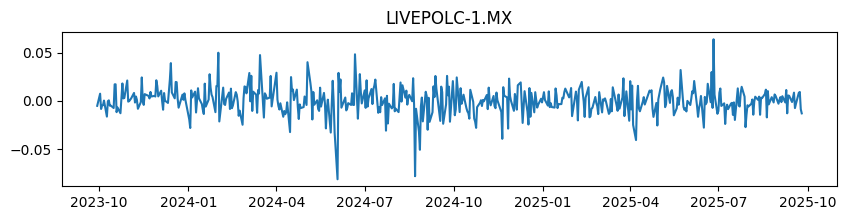

In [10]:
plt.figure(figsize=(10,2))
plt.title("LIVEPOLC-1.MX")
plt.plot(df_precios["Rendimientos"])
plt.show()

9


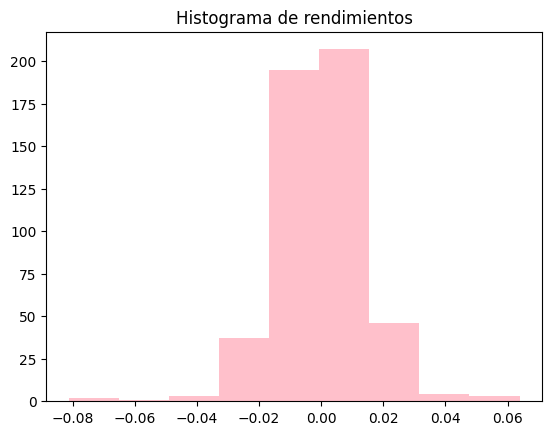

In [11]:
rendimientos = df_precios["Rendimientos"]

# Numero minimo de clases segun la regla de sturge
largo = len(rendimientos)
c = math.log(largo)/math.log(2)

# Entero más cercano hacia arriba
c = math.ceil(c)
print(c)

# Realizar histograma
plt.title("Histograma de rendimientos")

plt.hist(rendimientos, bins=c, color = "pink")
plt.show()

In [12]:
# Media
Mu = sum(rendimientos)/largo
print("El rendimiento esperado diario es de:", Mu)

# Desviación estandar
DE = math.sqrt(sum((rendimientos - Mu)**2)/(largo - 1))
print("La desviación estandar diaria es de:", DE)

# Sesgo
S = (largo/((largo-1)*(largo-2))) * sum(((rendimientos - Mu)/DE)**3)
print("El sesgo diario es de:", S)

# Kurtosis
K = (sum((rendimientos - Mu)**4))/((largo-1)*DE**4)
print("La kurtosis diaria es de:", K)

El rendimiento esperado diario es de: 0.0001041978579582386
La desviación estandar diaria es de: 0.014470597161549978
El sesgo diario es de: -0.41802359872754935
La kurtosis diaria es de: 7.492984966784337


In [13]:
# Media
Mu = rendimientos.mean()
print("El rendimiento esperado diario es de:", Mu)

# Desviación estandar
DE = rendimientos.std()
print("La desviación estandar diaria es de:", DE)

# Sesgo
S = skew(rendimientos, bias=False)
print("El sesgo diario es de:", S)

# Kurtosis
K = kurtosis(rendimientos, fisher=False, bias=False)
print("La kurtosis diaria es de:", K)

El rendimiento esperado diario es de: 0.00010419785795823863
La desviación estandar diaria es de: 0.014470597161549985
El sesgo diario es de: -0.4180235987275494
La kurtosis diaria es de: 7.565798102866736


In [14]:
# Prueba de hipotesis Jarque-Bera

# Calcular el estadistico
JB = largo*(S**2/6 + (K-3)**2/24)

# p_value
p_value = chi2.sf(JB, 2)

# valor de significancia del 0.05
alfa = 0.05

print("El estadistico de Jarque-Bera es de:", JB)
print("El p_value es de:", p_value)
print("Con un nivel de significancia", alfa, "se tiene que:")

if p_value > alfa:
    print("No rechazamos la hipotesis H0 ya que p_value= ", p_value, "> alfa =", alfa)
    print("La distribucion es normal")
else:
    print("Rechazamos la hipotesis H0 ya que p_value= ", p_value, "<= alfa =", alfa)
    print("La distribucion no es normal")

El estadistico de Jarque-Bera es de: 447.0688600746656
El p_value es de: 8.322053806255748e-98
Con un nivel de significancia 0.05 se tiene que:
Rechazamos la hipotesis H0 ya que p_value=  8.322053806255748e-98 <= alfa = 0.05
La distribucion no es normal


In [15]:
JB_python, p_value_python = jarque_bera(rendimientos)

print("El estadistico de Jarque-Bera es de:", JB_python)
print("El p_value es de:", p_value_python)

if p_value_python > alfa:
    print("No rechazamos la hipotesis H0 ya que p_value= ", p_value_python, "> alfa =", alfa)
    print("La distribucion es normal")
else:
    print("Rechazamos la hipotesis H0 ya que p_value= ", p_value_python, "<= alfa =", alfa)
    print("La distribucion no es normal")

El estadistico de Jarque-Bera es de: 436.1107302813488
El p_value es de: 1.994151594069408e-95
Rechazamos la hipotesis H0 ya que p_value=  1.994151594069408e-95 <= alfa = 0.05
La distribucion no es normal


# **Volatilidad**

In [16]:
df_precios = pd.DataFrame()
activo = 'LIVEPOLC-1.MX'
df_precios["Accion"] = pd.DataFrame(yf.Ticker(activo).history(start="2023-05-24",
                                                                   end="2025-09-11")["Close"])
df_precios

,Accion
Date,
2023-05-24 00:00:00-06:00,98.698761
2023-05-25 00:00:00-06:00,98.641846
2023-05-26 00:00:00-06:00,98.461639
2023-05-29 00:00:00-06:00,98.622879
2023-05-30 00:00:00-06:00,97.285530
...,...
2025-09-04 00:00:00-06:00,91.114479
2025-09-05 00:00:00-06:00,91.558464
2025-09-08 00:00:00-06:00,91.410469


In [17]:
df_precios['RI'] = np.log(df_precios['Accion']/df_precios['Accion'].shift(1))
df_precios.dropna(inplace=True)
df_precios

,Accion,RI
Date,,
2023-05-25 00:00:00-06:00,98.641846,-0.000577
2023-05-26 00:00:00-06:00,98.461639,-0.001829
2023-05-29 00:00:00-06:00,98.622879,0.001636
2023-05-30 00:00:00-06:00,97.285530,-0.013653
2023-05-31 00:00:00-06:00,98.091728,0.008253
...,...,...
2025-09-04 00:00:00-06:00,91.114479,-0.001299
2025-09-05 00:00:00-06:00,91.558464,0.004861
2025-09-08 00:00:00-06:00,91.410469,-0.001618


10


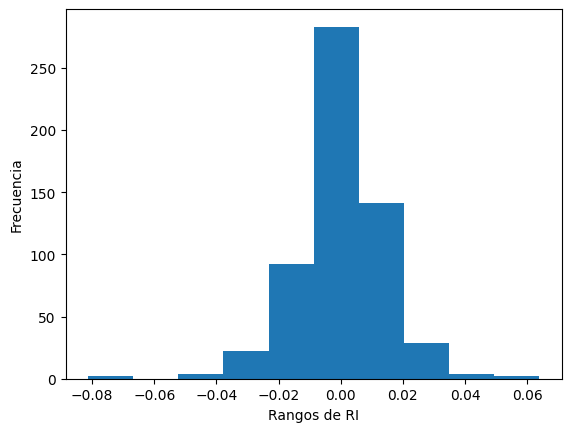

In [18]:
# Histograma
plt.xlabel("Rangos de RI")
plt.ylabel("Frecuencia")

# Intervalos
largo = len(df_precios['RI'])
c = math.log(largo)/math.log(2)
c = math.ceil(c)
print(c)

plt.hist(df_precios['RI'], bins=c)
plt.show()

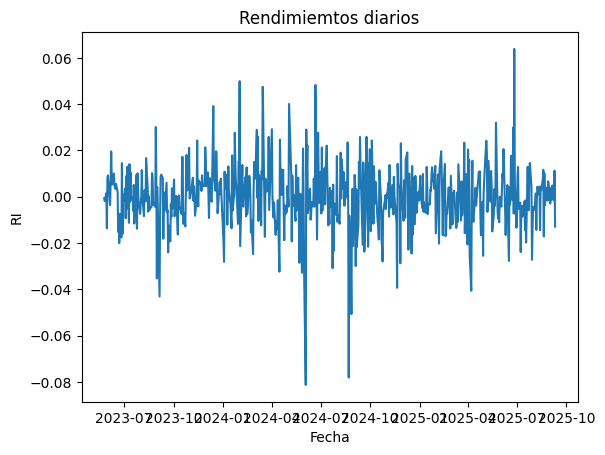

In [19]:
plt.title("Rendimiemtos diarios")
plt.xlabel("Fecha")
plt.ylabel("RI")

plt.plot(df_precios['RI'])
plt.show()

In [20]:
# Volatilidad Historica
media = sum(df_precios['RI']/len(df_precios['RI']))
print("La media de los rendimientos diarios es de:", media)

# Desviacion insesgada
vol_sma = np.sqrt(sum((df_precios['RI'] - media)**2)/(len(df_precios['RI']-1)))
print("La volatilidad historica es de:", vol_sma)

vol_ri2 = np.sqrt(sum((df_precios['RI'])**2)/len(df_precios['RI']))
print("La volatilidad historica es de:", vol_ri2)

La media de los rendimientos diarios es de: -0.00013528965092031816
La volatilidad historica es de: 0.014117660914487172
La volatilidad historica es de: 0.014118309140477302


In [21]:
# Metodo de ponderacion
df_precios['i'] = range(1,len(df_precios['RI'])+1)
df_precios['wi'] = df_precios['i']/df_precios['i'].sum()

df_precios

,Accion,RI,i,wi
Date,,,,
2023-05-25 00:00:00-06:00,98.641846,-0.000577,1,0.000006
2023-05-26 00:00:00-06:00,98.461639,-0.001829,2,0.000012
2023-05-29 00:00:00-06:00,98.622879,0.001636,3,0.000018
2023-05-30 00:00:00-06:00,97.285530,-0.013653,4,0.000024
2023-05-31 00:00:00-06:00,98.091728,0.008253,5,0.000030
...,...,...,...,...
2025-09-04 00:00:00-06:00,91.114479,-0.001299,575,0.003424
2025-09-05 00:00:00-06:00,91.558464,0.004861,576,0.003430
2025-09-08 00:00:00-06:00,91.410469,-0.001618,577,0.003436


In [22]:
vol_wma = np.sqrt(sum(((df_precios['RI']-media)**2)*df_precios['wi']))

print("La volatilidad wma es de:", vol_wma)

La volatilidad wma es de: 0.014217706192051094


# **Volatilidad dinamica método SMA (Simple)**

In [23]:
sma_n = 60
df_precios[f'sma_{sma_n}'] = df_precios['RI'].rolling(window=sma_n).std().shift(1)
df_precios.head(40)

,Accion,RI,i,wi,sma_60
Date,,,,,
2023-05-25 00:00:00-06:00,98.641846,-0.000577,1,0.000006,NaN
2023-05-26 00:00:00-06:00,98.461639,-0.001829,2,0.000012,NaN
2023-05-29 00:00:00-06:00,98.622879,0.001636,3,0.000018,NaN
2023-05-30 00:00:00-06:00,97.285530,-0.013653,4,0.000024,NaN
2023-05-31 00:00:00-06:00,98.091728,0.008253,5,0.000030,NaN
2023-06-01 00:00:00-06:00,99.002266,0.009240,6,0.000036,NaN
2023-06-02 00:00:00-06:00,99.590324,0.005922,7,0.000042,NaN
2023-06-05 00:00:00-06:00,99.229912,-0.003626,8,0.000048,NaN
2023-06-06 00:00:00-06:00,99.874878,0.006479,9,0.000054,NaN


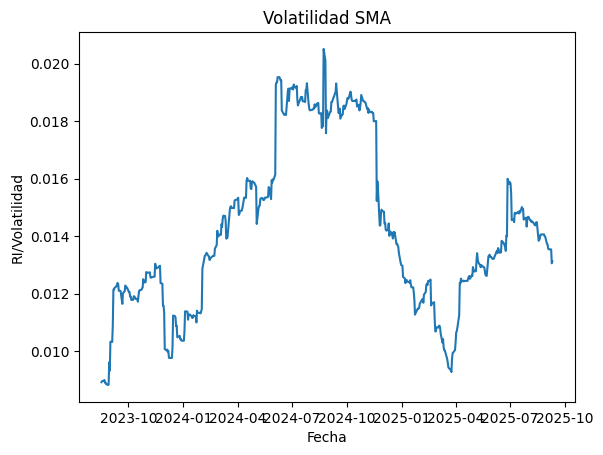

In [24]:
plt.title("Volatilidad SMA")
plt.xlabel("Fecha")
plt.ylabel("RI/Volatilidad")

plt.plot(df_precios['sma_60'])
plt.show()


# **Volatilidad dinamica método de WMA**

In [25]:
np.arange(1,10)

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [26]:
wma_n = 60

ri_shifted = df_precios['RI'].shift(1)

def std_wma(ri):
  n = len(ri)
  if n == 0:
    return np.nan
  i = np.arange(1,n+1)
  wi = i/sum(i)
  media = ri.mean()
  var_ponderada = sum(wi*(ri-media)**2)

  return np.sqrt(var_ponderada)


df_precios[f'std_wma{wma_n}'] = [std_wma(ri_shifted.iloc[i-wma_n+1:i+1])
                                if i >= wma_n else np.nan for i in range(len(df_precios))]

df_precios

,Accion,RI,i,wi,sma_60,std_wma60
Date,,,,,,
2023-05-25 00:00:00-06:00,98.641846,-0.000577,1,0.000006,NaN,NaN
2023-05-26 00:00:00-06:00,98.461639,-0.001829,2,0.000012,NaN,NaN
2023-05-29 00:00:00-06:00,98.622879,0.001636,3,0.000018,NaN,NaN
2023-05-30 00:00:00-06:00,97.285530,-0.013653,4,0.000024,NaN,NaN
2023-05-31 00:00:00-06:00,98.091728,0.008253,5,0.000030,NaN,NaN
...,...,...,...,...,...,...
2025-09-04 00:00:00-06:00,91.114479,-0.001299,575,0.003424,0.013542,0.010538
2025-09-05 00:00:00-06:00,91.558464,0.004861,576,0.003430,0.013537,0.010256
2025-09-08 00:00:00-06:00,91.410469,-0.001618,577,0.003436,0.013536,0.010009


# **Exponentionally weighted moving average GARCH(1,1)**

In [27]:
lamda = 0.94
vol = [df_precios['RI'].iloc[0]**2]

for i in range(1,len(df_precios)):
  vol_t = (lamda*vol[-1]) + ((1-lamda)*(df_precios['RI'].iloc[i]**2))
  vol.append(vol_t)

df_precios['EWMA'] = np.sqrt(vol)

df_precios


,Accion,RI,i,wi,sma_60,std_wma60,EWMA
Date,,,,,,,
2023-05-25 00:00:00-06:00,98.641846,-0.000577,1,0.000006,NaN,NaN,0.000577
2023-05-26 00:00:00-06:00,98.461639,-0.001829,2,0.000012,NaN,NaN,0.000717
2023-05-29 00:00:00-06:00,98.622879,0.001636,3,0.000018,NaN,NaN,0.000802
2023-05-30 00:00:00-06:00,97.285530,-0.013653,4,0.000024,NaN,NaN,0.003433
2023-05-31 00:00:00-06:00,98.091728,0.008253,5,0.000030,NaN,NaN,0.003895
...,...,...,...,...,...,...,...
2025-09-04 00:00:00-06:00,91.114479,-0.001299,575,0.003424,0.013542,0.010538,0.008797
2025-09-05 00:00:00-06:00,91.558464,0.004861,576,0.003430,0.013537,0.010256,0.008611
2025-09-08 00:00:00-06:00,91.410469,-0.001618,577,0.003436,0.013536,0.010009,0.008358


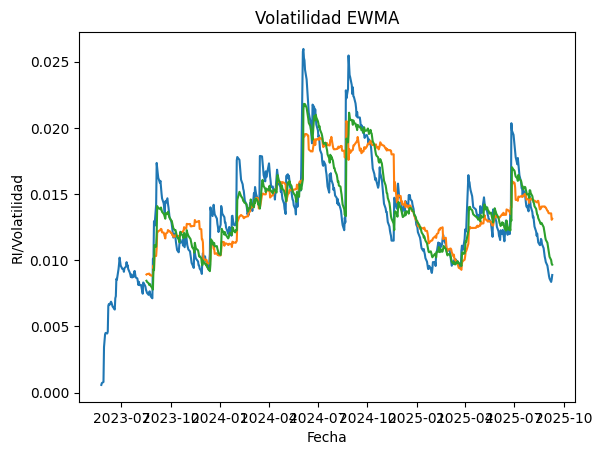

In [28]:
plt.title("Volatilidad EWMA")
plt.xlabel("Fecha")
plt.ylabel("RI/Volatilidad")

plt.plot(df_precios['EWMA'])
plt.plot(df_precios['sma_60'])
plt.plot(df_precios['std_wma60'])
plt.show()


In [29]:
df_precios = pd.DataFrame()

activos = ["LIVEPOLC-1.MX","GFINBURO.MX"]

for i in activos:
  df_precios[i] = pd.DataFrame(yf.Ticker(i).history(start="2023-05-24",
                                                                   end="2025-08-27")["Close"])

for i in activos:
  df_precios[f"ri_{i}"] = np.log(df_precios[i]).diff()

df_precios = df_precios.dropna()
df_precios

,LIVEPOLC-1.MX,GFINBURO.MX,ri_LIVEPOLC-1.MX,ri_GFINBURO.MX
Date,,,,
2023-05-25 00:00:00-06:00,98.641853,39.589298,-0.000577,0.002977
2023-05-26 00:00:00-06:00,98.461639,40.001179,-0.001829,0.010350
2023-05-29 00:00:00-06:00,98.622887,39.824661,0.001636,-0.004423
2023-05-30 00:00:00-06:00,97.285522,39.569687,-0.013653,-0.006423
2023-05-31 00:00:00-06:00,98.091728,38.569416,0.008253,-0.025604
...,...,...,...,...
2025-08-20 00:00:00-06:00,89.091911,48.520000,-0.017128,-0.000618
2025-08-21 00:00:00-06:00,89.999596,48.230000,0.010137,-0.005995
2025-08-22 00:00:00-06:00,89.674011,48.759998,-0.003624,0.010929


In [30]:
St_liv = df_precios['LIVEPOLC-1.MX'].iloc[-1]
St_inb = df_precios['GFINBURO.MX'].iloc[-1]

print("EL ultimo precio de liverpool es de:", St_liv)
print("EL ultimo precio de inbursa es es de:", St_inb)

media_liv = df_precios['ri_LIVEPOLC-1.MX'].mean()
media_inb = df_precios['ri_GFINBURO.MX'].mean()

print("La media de liverpool es de:", media_liv)
print("La media de inbursa es de:", media_inb)

vol_liv = df_precios['ri_LIVEPOLC-1.MX'].std()
vol_inb = df_precios['ri_GFINBURO.MX'].std()

print("La volatilidad de liverpool es de:", vol_liv)
print("La volatilidad de inbursa es de:", vol_inb)


EL ultimo precio de liverpool es de: 90.11798858642578
EL ultimo precio de inbursa es es de: 49.04999923706055
La media de liverpool es de: -0.00016012767552207386
La media de inbursa es de: 0.0003824967874862208
La volatilidad de liverpool es de: 0.014240015284439106
La volatilidad de inbursa es de: 0.020044083563403172


In [31]:
# VaR parametrico, sin media, a un dia para
VaRP_SM_liv_1d = -St_liv * vol_liv * norm.ppf(1-0.99)
print("EL VaR parametrico, sin media, a un dia de liverpol es de:", VaRP_SM_liv_1d)

VaRP_SM_inb_1d = -St_inb * vol_inb * norm.ppf(1-0.99)
print("EL VaR parametrico, sin media, a un dia de Inbursa es de:", VaRP_SM_inb_1d)

# VaR parametrico, con media, a un dia para
VaRP_CM_liv_1d = -St_liv * (media_liv + vol_liv * norm.ppf(1-0.99))
print("EL VaR parametrico, con media, a un dia de liverpol es d:", VaRP_CM_liv_1d)

VaRP_CM_inb_1d = -St_inb * (media_inb + vol_inb * norm.ppf(1-0.99))
print("EL VaR parametrico, con media, a un dia de Inbursa es de:", VaRP_CM_inb_1d)


# VaR historico a un dia para
VaRH_liv_1d = -St_liv * np.percentile(df_precios["ri_LIVEPOLC-1.MX"],1)
print("EL VaR historico a un dia de liveerpol es de:", VaRH_liv_1d)

VaRH_inb_1d = -St_inb * np.percentile(df_precios["ri_GFINBURO.MX"],1)
print("EL VaR historico a un dia de liveerpol es de:", VaRH_inb_1d)

EL VaR parametrico, sin media, a un dia de liverpol es de: 2.985359270449094
EL VaR parametrico, sin media, a un dia de Inbursa es de: 2.287177488039924
EL VaR parametrico, con media, a un dia de liverpol es d: 2.999789654484163
EL VaR parametrico, con media, a un dia de Inbursa es de: 2.268416020905547
EL VaR historico a un dia de liveerpol es de: 3.3010229534081734
EL VaR historico a un dia de liveerpol es de: 2.174062440262459


Lo maximo que puedo perder en un dia en liverpool es 3 pesos y en inbursa 2 pesos con un nivel de confianza del 99%

<function matplotlib.pyplot.show(close=None, block=None)>

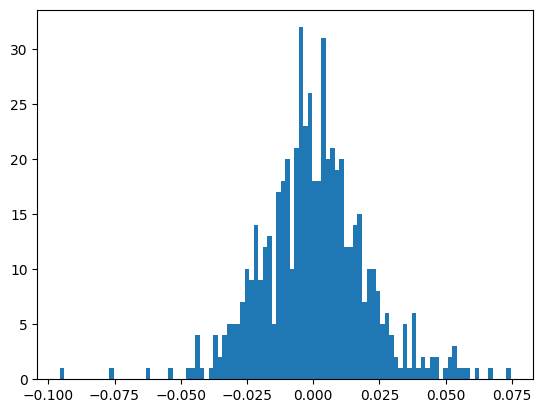

In [32]:
plt.hist(df_precios["ri_GFINBURO.MX"],bins=100)
plt.show

In [33]:
# VaR parametrico, sin media, a un año para
VaRP_SM_liv_1a = - St_liv * vol_liv * np.sqrt(255) * norm.ppf(1-0.99)
print("EL VaR parametrico, sin media, a un año de liverpol es de:", VaRP_SM_liv_1a)

VaRP_SM_inb_1a = - St_inb * vol_inb * np.sqrt(255) *  norm.ppf(1-0.99)
print("EL VaR parametrico, sin media, a un año de Inbursa es de:", VaRP_SM_inb_1a)


#VaR parametrico, con media, a un año para
VaRP_CM_liv_1a = - St_liv * ((255 * media_liv) + (np.sqrt(255) * vol_liv) * norm.ppf(1-0.99))
print("EL VaR parametrico, con media, a un año con media de liverpol es de:", VaRP_CM_liv_1a)

VaRP_CM_inb_1a = - St_inb * ((255 * media_inb) + (np.sqrt(255) * vol_inb) * norm.ppf(1-0.99))
print("EL VaR parametrico, con media, a un año con media de Inbursa es de:", VaRP_CM_inb_1a)


# VaR historico a un año para
VaRH_liv_1a = -St_liv * np.sqrt(255) * np.percentile(df_precios["ri_LIVEPOLC-1.MX"],1)
print("EL VaR historico a un año de liveerpol es de:", VaRH_liv_1a)

VaRH_inb_1a = -St_inb * np.sqrt(255) * np.percentile(df_precios["ri_GFINBURO.MX"],1)
print("EL VaR historico a un año de liveerpol es de:", VaRH_inb_1a)

EL VaR parametrico, sin media, a un año de liverpol es de: 47.672364565672304
EL VaR parametrico, sin media, a un año de Inbursa es de: 36.523295576359715
EL VaR parametrico, con media, a un año con media de liverpol es de: 51.35211249461494
EL VaR parametrico, con media, a un año con media de Inbursa es de: 31.739121457093518
EL VaR historico a un año de liveerpol es de: 52.71310935077291
EL VaR historico a un año de liveerpol es de: 34.71699311591932


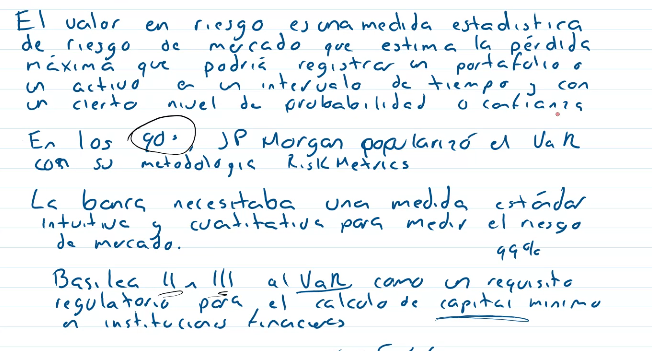

In [34]:
# Portafolio parametrico
capital = 200 * St_liv +  300 * St_inb
print(f"Valor del portafolio", capital)

VaR_p = 200 * VaRP_SM_liv_1d + 300 * VaRP_SM_inb_1d
print(f"Valor del VaR", VaR_p)

Valor del portafolio 32738.59748840332
Valor del VaR 1283.225100501796


In [35]:
wi = [0.6, 0.4]

media = np.array([media_liv, media_inb])

matriz_cov = df_precios[["ri_LIVEPOLC-1.MX","ri_GFINBURO.MX"]].cov()

print(wi)
print(media)
print(matriz_cov)

rendimiento_portafolio = wi @ media
print(f"Rendimiento portafolio", rendimiento_portafolio)

volatilidad_portafolio = np.sqrt(wi @ matriz_cov @ wi)
print(f"Volatilidad portafolio", volatilidad_portafolio)

[0.6, 0.4]
[-0.00016013  0.0003825 ]
                  ri_LIVEPOLC-1.MX  ri_GFINBURO.MX
ri_LIVEPOLC-1.MX          0.000203        0.000076
ri_GFINBURO.MX            0.000076        0.000402
Rendimiento portafolio 5.6922109681243995e-05
Volatilidad portafolio 0.013190513409232912


In [36]:
capital = 1000000

wi = [0.4,0.6]

monto = [capital * i for i in wi]

precios = [df_precios[i].iloc[-1] for i in activos]

n_activos = [i / j for i, j in zip(monto, precios)]
n_activos = [round(i, 0) for i in n_activos]

media = np.array([df_precios[f"ri_{i}"].mean() for i in activos])

matrix_cov = df_precios[["ri_LIVEPOLC-1.MX","ri_GFINBURO.MX"]].cov()

Portafolio = pd.DataFrame(zip(activos,monto,precios,n_activos,media),
                          columns=['activos',
                                   'monto',
                                   'precios',
                                   'n_activos',
                                   'media'])
print(Portafolio)

rendimientos_port = wi @ media
volatilidad_port = np.sqrt(wi @ matrix_cov @ wi)

print(f"Rendimiento portafolio", rendimientos_port)
print(f"Volatilidad portafolio", volatilidad_port)

VaR = -capital*volatilidad_port*norm.ppf(1-0.99)
print(f"VaR", VaR)

VaR_sum = 4379 * VaRP_SM_liv_1d + 12232 * VaRP_SM_inb_1d
print(f"VaRlib + VaRinb", VaR_sum)

         activos     monto    precios  n_activos     media
0  LIVEPOLC-1.MX  400000.0  90.117989     4439.0 -0.000160
1    GFINBURO.MX  600000.0  49.049999    12232.0  0.000382
Rendimiento portafolio 0.00016544700228290291
Volatilidad portafolio 0.01462146005425858
VaR 34014.60251259752
VaRlib + VaRinb 41049.64327900093
